# EDA – Segmentacja i profilowanie regionalnych rynków motoryzacyjnych w Polsce

**Zespół:** Check Engine Team · **Klient:** Sieć autokomisów

Dane są pobierane bezpośrednio z publicznego API CEPiK (`https://api.cepik.gov.pl/pojazdy`) przy każdym uruchomieniu notebooka. Nie ma źródła zastępczego – jeśli API nie zwróci wystarczającej liczby rekordów, notebook zgłasza błąd zamiast używać danych wygenerowanych.

Ścieżki są względne do katalogu `notebooks/`. Kopia pobranych danych zapisywana jest w `../data/raw/`, wynik czyszczenia w `../data/processed/`.

In [1]:
import warnings
import time
import ssl
from pathlib import Path

import requests
import urllib3
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    display
except NameError:  # poza Jupyterem (np. skrypt)
    def display(obj):
        print(obj)

warnings.filterwarnings("ignore")
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ROOT = Path("..").resolve()
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)
print("Biblioteki załadowane. Katalog danych surowych:", RAW_DIR)

Biblioteki załadowane. Katalog danych surowych: /data/raw


## 1. Pobieranie danych z API CEPiK

Parametry zapytania zgodne z notebookiem `Untitled23`: województwo (kod), zakres dat według typu daty 1 (pierwsza rejestracja), tylko zarejestrowane pojazdy, limit 500 rekordów na stronę.

> **Ważne dla interpretacji:** każde zapytanie zwraca maksymalnie 500 rekordów (strona 1). Zbiór jest więc **próbką** pierwszych rekordów zwróconych przez API dla każdego województwa i okresu, a nie pełną populacją rejestracji. Liczba rekordów na województwo jest wyrównana przez limit, co wpływa na porównania regionalne (sekcja 10).

Połączenie używa adaptera z obniżonym poziomem bezpieczeństwa SSL (`SECLEVEL=1`) i `verify=False`, bo serwer CEPiK tego wymaga – zgodnie z `Untitled23`.

In [2]:
BASE_URL = "https://api.cepik.gov.pl/pojazdy"

SLOWNIK_WOJEWODZTW = {
    "02": "DOLNOŚLĄSKIE", "04": "KUJAWSKO-POMORSKIE", "06": "LUBELSKIE", "08": "LUBUSKIE",
    "10": "ŁÓDZKIE", "12": "MAŁOPOLSKIE", "14": "MAZOWIECKIE", "16": "OPOLSKIE",
    "18": "PODKARPACKIE", "20": "PODLASKIE", "22": "POMORSKIE", "24": "ŚLĄSKIE",
    "26": "ŚWIĘTOKRZYSKIE", "28": "WARMIŃSKO-MAZURSKIE", "30": "WIELKOPOLSKIE", "32": "ZACHODNIOPOMORSKIE",
}

# Przedziały dat (typ-daty=1 → data pierwszej rejestracji); 2025 tylko do 30.06
DATE_INTERVALS = [
    ("20230101", "20231231"),
    ("20240101", "20241231"),
    ("20250101", "20250630"),
]

REQUIRED_COLS = [
    "rodzaj-paliwa", "rodzaj-pierwszego-paliwa-alternatywnego", "rodzaj-drugiego-paliwa-alternatywnego",
    "marka", "model", "rok-produkcji", "data-pierwszej-rejestracji-w-kraju",
    "wlasciciel-wojewodztwo", "rejestracja-wojewodztwo", "poziom-emisji-co2",
    "moc-netto-silnika", "rodzaj-pojazdu", "pojemnosc-skokowa-silnika", "masa-wlasna",
]

MIN_RECORDS = 5000  # poniżej tej liczby uznajemy pobieranie za niepełne i przerywamy


class WeakDHAdapter(HTTPAdapter):
    """Adapter TLS dla serwera CEPiK (obniżony SECLEVEL, bez weryfikacji certyfikatu)."""
    def init_poolmanager(self, *args, **kwargs):
        ctx = urllib3.util.ssl_.create_urllib3_context()
        ctx.set_ciphers("DEFAULT:@SECLEVEL=1")
        ctx.check_hostname = False
        ctx.verify_mode = ssl.CERT_NONE
        kwargs["ssl_context"] = ctx
        super().init_poolmanager(*args, **kwargs)


def make_session():
    session = requests.Session()
    retries = Retry(total=10, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504])
    session.mount("https://", WeakDHAdapter(max_retries=retries))
    return session


def fetch_cepik(woj_dict, date_intervals, pause=3.5, timeout=20):
    """Pobiera rekordy z API CEPiK. Zwraca (DataFrame, log). Nie używa danych zastępczych."""
    session = make_session()
    records, log = [], []

    for kod, nazwa in woj_dict.items():
        for d_od, d_do in date_intervals:
            params = {
                "wojewodztwo": kod,
                "data-od": d_od,
                "data-do": d_do,
                "typ-daty": "1",
                "tylko-zarejestrowane": "true",
                "limit": "500",
                "page": "1",
            }
            try:
                resp = session.get(BASE_URL, params=params, timeout=timeout, verify=False)
                if resp.status_code == 404:
                    log.append((nazwa, d_od, d_do, "brak danych (404)", 0))
                    continue
                resp.raise_for_status()
                try:
                    data_list = resp.json().get("data", [])
                except ValueError:
                    log.append((nazwa, d_od, d_do, "uszkodzony JSON – pominięto", 0))
                    continue

                for item in data_list:
                    attr = item.get("attributes", {})
                    row = {col: attr.get(col) for col in REQUIRED_COLS}
                    if not row["rejestracja-wojewodztwo"]:
                        row["rejestracja-wojewodztwo"] = nazwa
                    records.append(row)

                log.append((nazwa, d_od, d_do, "ok", len(data_list)))
                time.sleep(pause)

            except Exception as e:  # błąd sieci / HTTP – zapisujemy, idziemy dalej
                log.append((nazwa, d_od, d_do, f"błąd: {type(e).__name__}", 0))

    return pd.DataFrame(records), pd.DataFrame(log, columns=["woj", "od", "do", "status", "rekordy"])

In [3]:
df_raw, fetch_log = fetch_cepik(SLOWNIK_WOJEWODZTW, DATE_INTERVALS)

print("Log pobierania:")
display(fetch_log)

if len(df_raw) < MIN_RECORDS:
    raise RuntimeError(
        f"Pobrano tylko {len(df_raw)} rekordów z API CEPiK (próg: {MIN_RECORDS}). "
        "Sprawdź połączenie lub dostępność API i uruchom notebook ponownie."
    )

RAW_CSV = RAW_DIR / "cepik_raw.csv"
df_raw.to_csv(RAW_CSV, index=False, sep=";")
print(f"Pobrano łącznie {len(df_raw):,} rekordów. Zapisano kopię: {RAW_CSV.name}")

Log pobierania:


,woj,od,do,status,rekordy
0,DOLNOŚLĄSKIE,20230101,20231231,ok,500
1,DOLNOŚLĄSKIE,20240101,20241231,ok,500
2,DOLNOŚLĄSKIE,20250101,20250630,ok,500
3,KUJAWSKO-POMORSKIE,20230101,20231231,ok,500
4,KUJAWSKO-POMORSKIE,20240101,20241231,ok,500
5,KUJAWSKO-POMORSKIE,20250101,20250630,ok,500
6,LUBELSKIE,20230101,20231231,ok,500
7,LUBELSKIE,20240101,20241231,ok,500
8,LUBELSKIE,20250101,20250630,ok,500
9,LUBUSKIE,20230101,20231231,uszkodzony JSON – pominięto,0


Pobrano łącznie 23,000 rekordów. Zapisano kopię: cepik_raw.csv


## 2. Podstawowy rzut oka – dane surowe
`shape`, `dtypes` i `describe()`.

In [13]:
print("Kształt (wiersze, kolumny):", df_raw.shape)
display(df_raw.dtypes.to_frame("dtype"))

num_cols = ["rok-produkcji", "pojemnosc-skokowa-silnika", "masa-wlasna"]
display(df_raw[num_cols].apply(pd.to_numeric, errors="coerce").describe().T)

Kształt (wiersze, kolumny): (23000, 14)


,dtype
rodzaj-paliwa,object
rodzaj-pierwszego-paliwa-alternatywnego,object
rodzaj-drugiego-paliwa-alternatywnego,object
marka,object
model,object
rok-produkcji,object
data-pierwszej-rejestracji-w-kraju,object
wlasciciel-wojewodztwo,object
rejestracja-wojewodztwo,object
poziom-emisji-co2,object


,count,mean,std,min,25%,50%,75%,max
rok-produkcji,"23,000.00","2,014.77",9.00,"1,937.00","2,009.00","2,016.00","2,022.00","2,025.00"
pojemnosc-skokowa-silnika,"20,834.00","2,238.02","2,222.63",1.00,"1,422.00","1,798.00","1,997.00","16,353.00"
masa-wlasna,"23,000.00","1,918.91","2,094.84",1.00,"1,211.00","1,467.00","1,790.00","36,000.00"


## 3. Brakujące wartości
Liczba i odsetek braków dla każdej kolumny oraz wzorzec braków.

,braki_n,braki_%
rodzaj-pierwszego-paliwa-alternatywnego,23000,100.00
rodzaj-drugiego-paliwa-alternatywnego,23000,100.00
poziom-emisji-co2,23000,100.00
moc-netto-silnika,23000,100.00
wlasciciel-wojewodztwo,23000,100.00
pojemnosc-skokowa-silnika,2166,9.42
rodzaj-paliwa,1896,8.24
marka,618,2.69
model,11,0.05
rok-produkcji,0,0.00


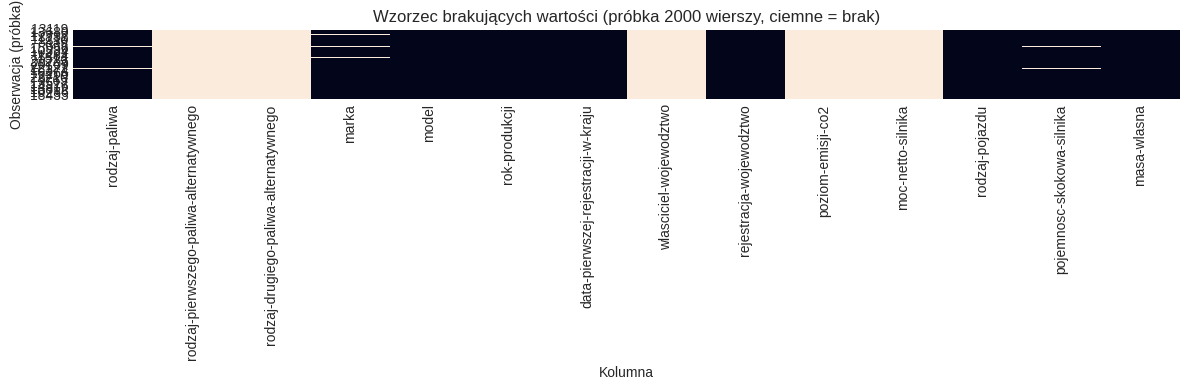

In [5]:
miss = pd.DataFrame({
    "braki_n": df_raw.isna().sum(),
    "braki_%": df_raw.isna().mean() * 100,
}).sort_values("braki_%", ascending=False)
display(miss.round(2))

sample = df_raw.sample(min(2000, len(df_raw)), random_state=0)
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(sample.isna(), cbar=False, ax=ax)
ax.set_title("Wzorzec brakujących wartości (próbka 2000 wierszy, ciemne = brak)")
ax.set_xlabel("Kolumna"); ax.set_ylabel("Obserwacja (próbka)")
plt.tight_layout(); plt.show()

**Interpretacja:** _(uzupełnić po uruchomieniu – np. czy kolumny `wlasciciel-wojewodztwo` i `poziom-emisji-co2` są puste, co potwierdza ograniczenia z raportu.)_

## 4. Czyszczenie i inżynieria cech

Reguły zgodne z `Untitled23` i raportem: filtr SAMOCHÓD OSOBOWY, masa 500–3500 kg, pojemność < 7000 cm³ (dodatkowo > 0, aby usunąć literówki typu 1 cm³), wiek ≥ 0. Cechy: `wiek_pojazdu`, `pochodzenie` (import / krajowy), uproszczony napęd `Naped`.

In [6]:
df_clean = df_raw.copy()
print(f"Początkowa liczba rekordów: {len(df_clean):,}")

df_clean = df_clean[df_clean["rodzaj-pojazdu"] == "SAMOCHÓD OSOBOWY"].copy()
print(f"Po filtrze SAMOCHÓD OSOBOWY: {len(df_clean):,}")

df_clean["rok-produkcji"] = pd.to_numeric(df_clean["rok-produkcji"], errors="coerce")
df_clean["data-pierwszej-rejestracji-w-kraju"] = pd.to_datetime(
    df_clean["data-pierwszej-rejestracji-w-kraju"], errors="coerce")
df_clean["pojemnosc-skokowa-silnika"] = pd.to_numeric(df_clean["pojemnosc-skokowa-silnika"], errors="coerce")
df_clean["masa-wlasna"] = pd.to_numeric(df_clean["masa-wlasna"], errors="coerce")
df_clean["poziom-emisji-co2"] = pd.to_numeric(df_clean["poziom-emisji-co2"], errors="coerce")
df_clean["moc-netto-silnika"] = pd.to_numeric(df_clean["moc-netto-silnika"], errors="coerce")

df_clean = df_clean[
    df_clean["masa-wlasna"].between(500, 3500)
    & (df_clean["pojemnosc-skokowa-silnika"] > 0)
    & (df_clean["pojemnosc-skokowa-silnika"] < 7000)
].copy()
print(f"Po filtrach masy i pojemności: {len(df_clean):,}")

df_clean["rok_rejestracji"] = df_clean["data-pierwszej-rejestracji-w-kraju"].dt.year
df_clean["wiek_pojazdu"] = df_clean["rok_rejestracji"] - df_clean["rok-produkcji"]
df_clean = df_clean[df_clean["wiek_pojazdu"].between(0, 60)].copy()
print(f"Po usunięciu błędnych wieków: {len(df_clean):,}")

# Uwaga: próg 1 roku z raportu – auto z wiekiem >1 traktowane jako import
df_clean["pochodzenie"] = np.where(df_clean["wiek_pojazdu"] > 1, "Import używany", "Krajowy (Nowy)")

def uprosc_naped(rodzaj):
    if pd.isna(rodzaj): return "Inne"
    if "ENERGIA ELEKTRYCZNA" in rodzaj: return "Elektryczny (BEV)"
    if "OLEJ NAPĘDOWY" in rodzaj: return "Diesel"
    if "BENZYNA" in rodzaj: return "Benzyna"
    return "Inne"

df_clean["Naped"] = df_clean["rodzaj-paliwa"].apply(uprosc_naped)
df_clean["woj"] = df_clean["rejestracja-wojewodztwo"]

print(f"\nLiczba rekordów po czyszczeniu: {len(df_clean):,}")
df_clean.to_csv(PROC_DIR / "pojazdy_clean.csv", index=False, sep=";")

Początkowa liczba rekordów: 23,000
Po filtrze SAMOCHÓD OSOBOWY: 16,126
Po filtrach masy i pojemności: 15,913
Po usunięciu błędnych wieków: 15,910

Liczba rekordów po czyszczeniu: 15,910


## 5. Podstawowy rzut oka – dane oczyszczone

In [7]:
print("Kształt:", df_clean.shape)
display(df_clean[["pojemnosc-skokowa-silnika", "masa-wlasna", "wiek_pojazdu", "moc-netto-silnika"]].describe().T)

Kształt: (15910, 19)


,count,mean,std,min,25%,50%,75%,max
pojemnosc-skokowa-silnika,"15,910.00","1,798.95",598.17,499.00,"1,490.00","1,685.00","1,994.00","6,417.00"
masa-wlasna,"15,910.00","1,482.37",300.84,520.00,"1,284.00","1,451.00","1,634.00","3,205.00"
wiek_pojazdu,"15,910.00",9.08,7.15,0.00,1.00,9.00,15.00,58.00
moc-netto-silnika,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Rozkłady zmiennych ciągłych
Histogram i boxplot dla wieku, pojemności, masy i mocy netto.

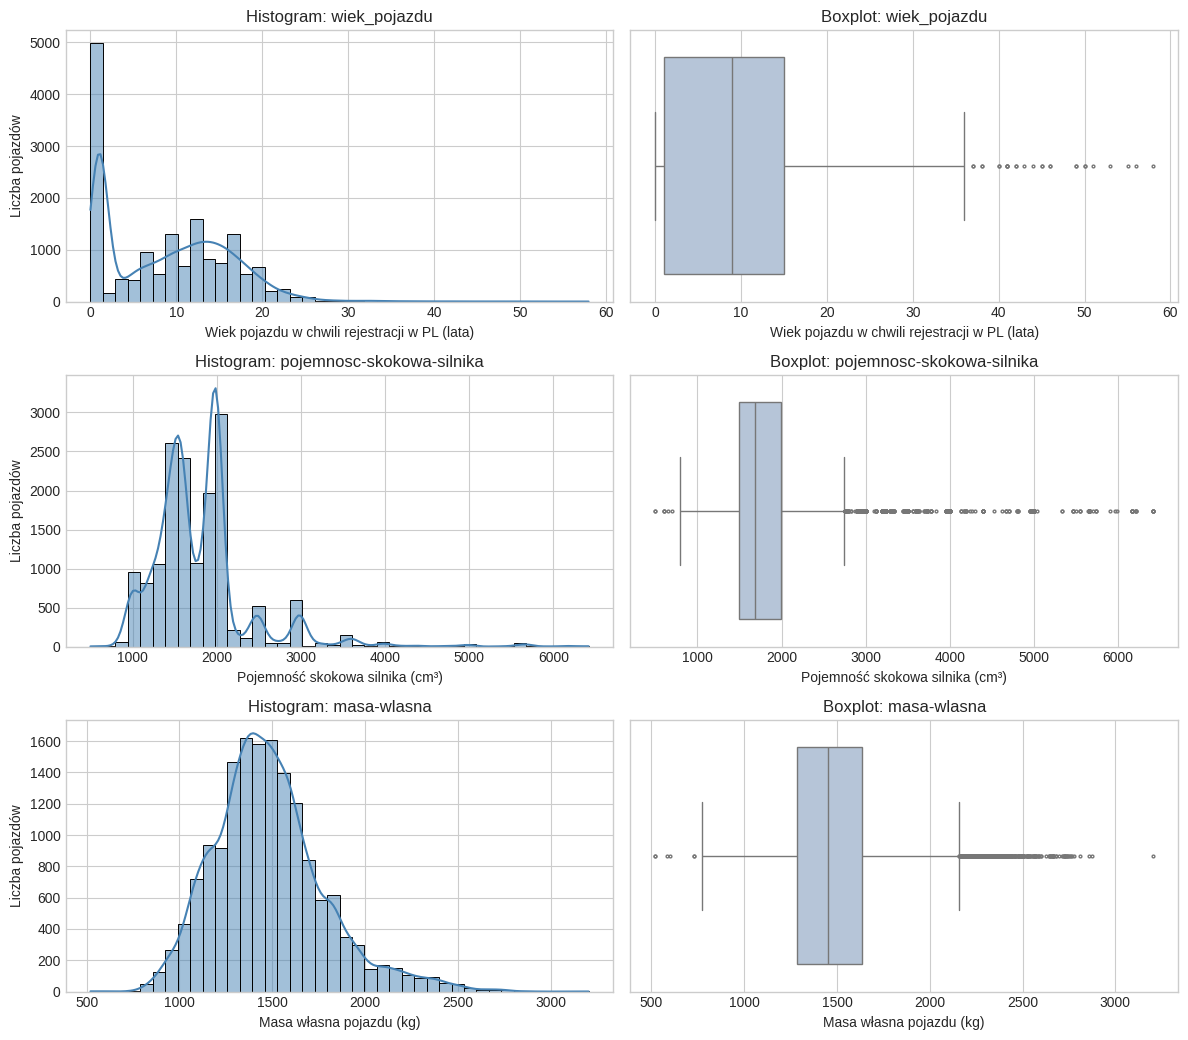

In [14]:
cont = {
    "wiek_pojazdu": ("Wiek pojazdu w chwili rejestracji w PL", "lata"),
    "pojemnosc-skokowa-silnika": ("Pojemność skokowa silnika", "cm³"),
    "masa-wlasna": ("Masa własna pojazdu", "kg")
}
fig, axes = plt.subplots(len(cont), 2, figsize=(12, 3.5 * len(cont)))
for i, (col, (label, unit)) in enumerate(cont.items()):
    s = df_clean[col].dropna()
    sns.histplot(s, bins=40, kde=True, ax=axes[i, 0], color="steelblue")
    axes[i, 0].set_title(f"Histogram: {col}")
    axes[i, 0].set_xlabel(f"{label} ({unit})"); axes[i, 0].set_ylabel("Liczba pojazdów")
    sns.boxplot(x=s, ax=axes[i, 1], color="lightsteelblue", fliersize=2)
    axes[i, 1].set_title(f"Boxplot: {col}")
    axes[i, 1].set_xlabel(f"{label} ({unit})")
plt.tight_layout(); plt.show()

**Interpretacja:** _(uzupełnić – np. czy rozkład wieku jest dwumodalny, co sugerowałoby dwa segmenty: nowe i importowane.)_

## 7. Zmienne kategoryczne
Tabele częstości i wykresy słupkowe: województwo, marka (Top 10), napęd, pochodzenie.


Województwo rejestracji


,n,%
woj,,
ZACHODNIOPOMORSKIE,1116,7.01
POMORSKIE,1109,6.97
DOLNOŚLĄSKIE,1101,6.92
ŚLĄSKIE,1101,6.92
ŁÓDZKIE,1051,6.61
KUJAWSKO-POMORSKIE,1041,6.54
MAZOWIECKIE,1028,6.46
OPOLSKIE,1025,6.44
WARMIŃSKO-MAZURSKIE,1021,6.42



Marka


,n,%
marka,,
TOYOTA,1616,10.16
VOLKSWAGEN,1529,9.61
AUDI,1177,7.40
FORD,1159,7.28
OPEL,1051,6.61
BMW,941,5.91
SKODA,931,5.85
MERCEDES-BENZ,808,5.08
KIA,700,4.40



Rodzaj napędu


,n,%
Naped,,
Benzyna,10465,65.78
Diesel,5439,34.19
Inne,3,0.02
Elektryczny (BEV),3,0.02



Pochodzenie


,n,%
pochodzenie,,
Import używany,10926,68.67
Krajowy (Nowy),4984,31.33


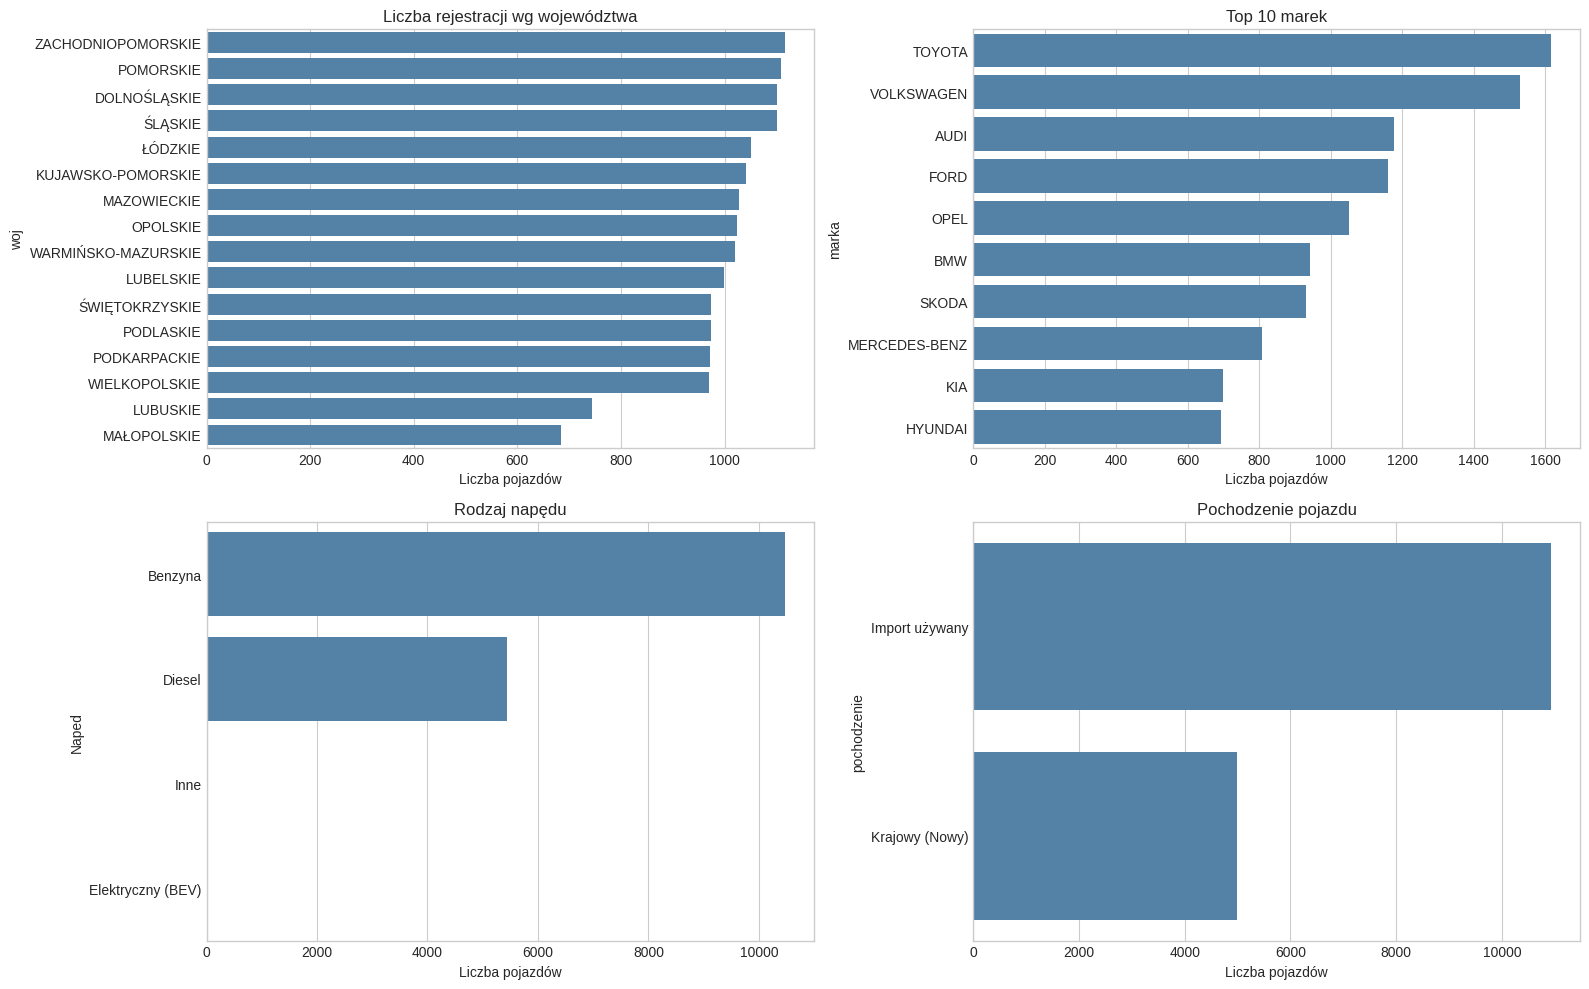

In [9]:
for col, title in [("woj", "Województwo rejestracji"),
                   ("marka", "Marka"),
                   ("Naped", "Rodzaj napędu"),
                   ("pochodzenie", "Pochodzenie")]:
    freq = df_clean[col].value_counts(dropna=False)
    if col == "marka":
        freq = freq.head(10)
    print(f"\n{title}")
    display(pd.DataFrame({"n": freq, "%": (freq / len(df_clean) * 100).round(2)}))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plots = [("woj", None, "Liczba rejestracji wg województwa", "Liczba pojazdów"),
         ("marka", 10, "Top 10 marek", "Liczba pojazdów"),
         ("Naped", None, "Rodzaj napędu", "Liczba pojazdów"),
         ("pochodzenie", None, "Pochodzenie pojazdu", "Liczba pojazdów")]
for ax, (col, n, title, xlabel) in zip(axes.flat, plots):
    vc = df_clean[col].value_counts()
    if n: vc = vc.head(n)
    sns.barplot(x=vc.values, y=vc.index, ax=ax, color="steelblue")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(col)
plt.tight_layout(); plt.show()

**Interpretacja:** _(uzupełnić – które województwa i marki dominują; jaki odsetek stanowi import.)_

## 8. Macierz korelacji
Korelacje Pearsona między zmiennymi numerycznymi.

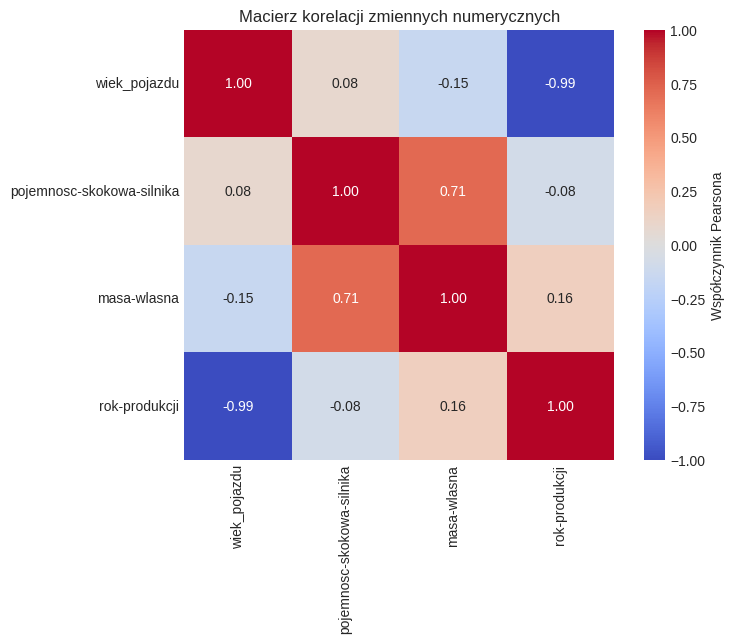

In [15]:
num = df_clean[["wiek_pojazdu", "pojemnosc-skokowa-silnika", "masa-wlasna",
                "rok-produkcji"]].apply(pd.to_numeric, errors="coerce")
corr = num.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Współczynnik Pearsona"}, ax=ax)
ax.set_title("Macierz korelacji zmiennych numerycznych")
plt.tight_layout(); plt.show()

**Interpretacja:** _(uzupełnić – `wiek_pojazdu` i `rok-produkcji` są skorelowane z definicji; istotne są korelacje pojemności z masą i mocą.)_

## 9. Zależności dwuwymiarowe istotne dla pytania badawczego
Pytania: (a) czy segment importowany ma większe silniki, (b) jak odsetek importu i diesla różni się między województwami.

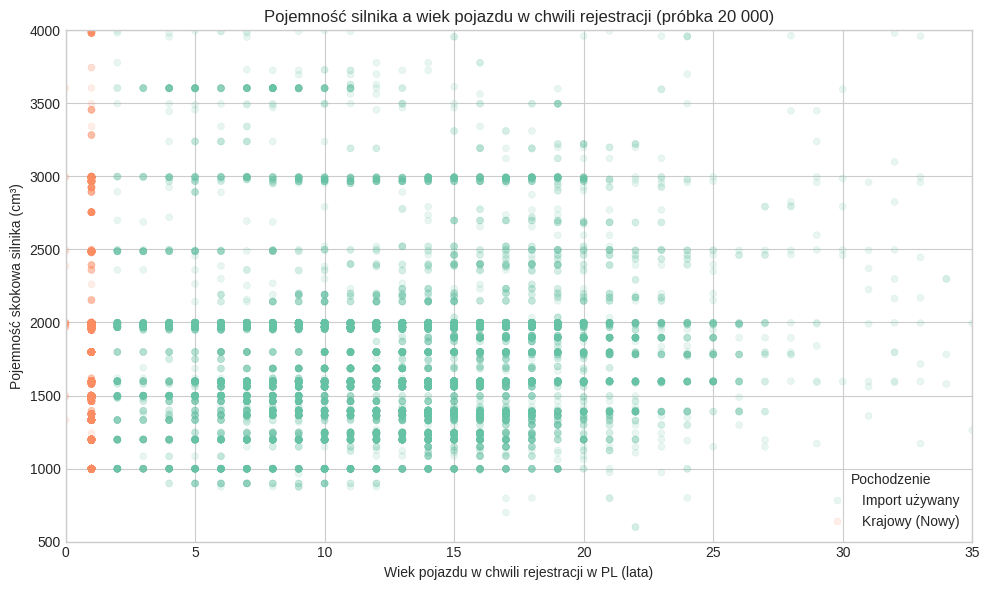

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_clean.sample(min(20000, len(df_clean)), random_state=0),
                x="wiek_pojazdu", y="pojemnosc-skokowa-silnika", hue="pochodzenie",
                alpha=0.15, s=25, edgecolor=None, palette="Set2", ax=ax)
ax.set_title("Pojemność silnika a wiek pojazdu w chwili rejestracji (próbka 20 000)")
ax.set_xlabel("Wiek pojazdu w chwili rejestracji w PL (lata)")
ax.set_ylabel("Pojemność skokowa silnika (cm³)")
ax.set_xlim(0, 35); ax.set_ylim(500, 4000)
ax.legend(title="Pochodzenie")
plt.tight_layout(); plt.show()

**Interpretacja:** _(uzupełnić – czy import ma większe jednostki napędowe.)_

,n,udzial_importu,udzial_diesla
woj,,,
LUBELSKIE,999,80.40,37.70
PODKARPACKIE,972,80.30,35.70
LUBUSKIE,745,76.10,37.20
ŚWIĘTOKRZYSKIE,973,74.50,40.20
WARMIŃSKO-MAZURSKIE,1021,73.80,36.80
OPOLSKIE,1025,73.10,37.60
PODLASKIE,973,70.70,32.10
WIELKOPOLSKIE,971,70.50,39.00
ZACHODNIOPOMORSKIE,1116,69.50,38.00


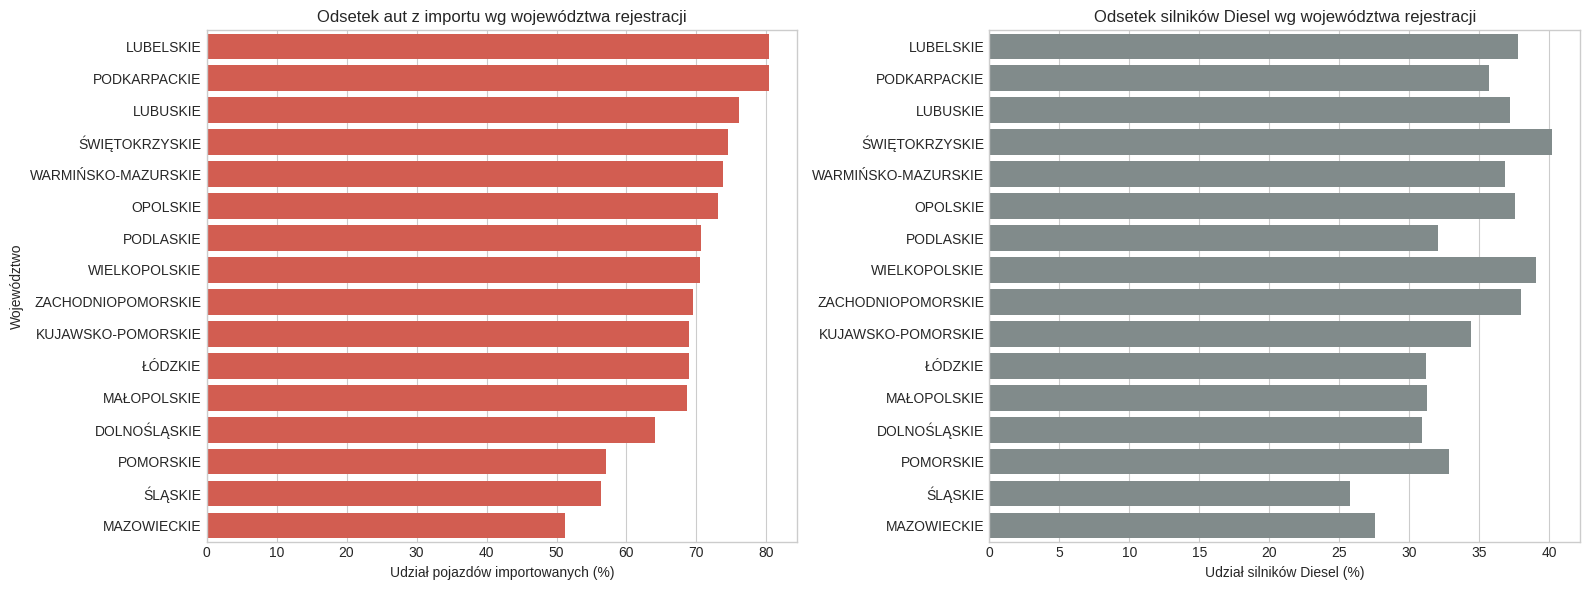

In [12]:
reg = (df_clean.groupby("woj")
         .agg(n=("woj", "size"),
              udzial_importu=("pochodzenie", lambda s: (s == "Import używany").mean() * 100),
              udzial_diesla=("Naped", lambda s: (s == "Diesel").mean() * 100))
         .query("n >= 100")
         .sort_values("udzial_importu", ascending=False))
display(reg.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=reg.reset_index(), x="udzial_importu", y="woj", color="#e74c3c", ax=axes[0])
axes[0].set_title("Odsetek aut z importu wg województwa rejestracji")
axes[0].set_xlabel("Udział pojazdów importowanych (%)"); axes[0].set_ylabel("Województwo")
sns.barplot(data=reg.reset_index(), x="udzial_diesla", y="woj", color="#7f8c8d", ax=axes[1])
axes[1].set_title("Odsetek silników Diesel wg województwa rejestracji")
axes[1].set_xlabel("Udział silników Diesel (%)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretacja:** _(uzupełnić – które regiony są „importowe” i „dieslowe”; uwaga na MAZOWIECKIE i WIELKOPOLSKIE, gdzie rejestracje poleasingowe zniekształcają obraz.)_

## 10. Podsumowanie i ograniczenia
- **Źródło:** API CEPiK, 16 województw, 3 okresy; zbiór to próbka (maks. 500 rekordów na zapytanie) – patrz sekcja 1.
- **Braki i czyszczenie:** sekcje 3–4.
- **Kluczowe obserwacje dla pytania badawczego:** sekcje 6–9.
- **Ograniczenia:** rejestracja w województwie to proxy miejsca sprzedaży; flaga importu opiera się na progu wieku 1 roku; wyniki regionalne zależą od limitu próbkowania.
- _(uzupełnić wnioski po uruchomieniu)_